# STT nhẹ — benchmark cô lập (Arduino UNO Q 4GB)

**Khác bản cũ (nguyên nhân gốc của "2GB RAM"):**
- Bản cũ đo RSS của *cả tiến trình Jupyter* (torch + CUDA + dataset + model cũ chưa giải phóng) → mọi model đều ~2.3GB.
- Bản này chạy **mỗi model trong một tiến trình con**, đo `ram_model` (delta khi nạp) và `ram_total_peak_mb` (đỉnh − lúc khởi động).
- Runtime nhẹ: faster-whisper int8 (CTranslate2), Vosk. Moonshine bằng torch chỉ để tham chiếu.
- CPU-only, 4 luồng (giống UNO Q 4 nhân). Số trên PC x86 chỉ là **ước lượng**, phải đo lại trên UNO Q.

In [5]:
%pip install -q faster-whisper vosk jiwer soundfile librosa psutil pandas matplotlib "datasets>=2.20.0" transformers

Note: you may need to restart the kernel to use updated packages.


In [6]:
import sys; sys.path.insert(0, ".")
from bench_common import *

DATA = prep_librispeech(200)   # ghi wav ra đĩa, tiến trình con đọc từng file (không giữ dataset trong RAM)

Resolving data files:   0%|          | 0/62 [00:00<?, ?it/s]

In [7]:
STT = [
    ("faster-whisper tiny.en int8",  "stt_fw",   {"size": "tiny.en"}),
    ("faster-whisper base.en int8",  "stt_fw",   {"size": "base.en"}),
    ("faster-whisper small.en int8", "stt_fw",   {"size": "small.en"}),
    ("vosk small-en-us-0.15",        "stt_vosk", {"model": "vosk-model-small-en-us-0.15"}),
    ("moonshine-tiny (torch, REF)",  "stt_hf",   {"repo": "UsefulSensors/moonshine-tiny"}),
]
for name, kind, params in STT:
    bench("stt", name, kind, {**params, "data_dir": DATA})

[done] faster-whisper tiny.en int8: ram_peak_mb=213.0, ram_total_peak_mb=246.4, rtf=0.03, wer=0.059
[done] faster-whisper base.en int8: ram_peak_mb=366.9, ram_total_peak_mb=400.0, rtf=0.061, wer=0.0449
[done] faster-whisper small.en int8: ram_peak_mb=678.9, ram_total_peak_mb=712.2, rtf=0.169, wer=0.0348
[done] vosk small-en-us-0.15: ram_peak_mb=193.9, ram_total_peak_mb=235.0, rtf=0.165, wer=0.109
[done] moonshine-tiny (torch, REF): ram_peak_mb=439.7, ram_total_peak_mb=859.3, rtf=0.053, wer=0.0399


In [8]:
df = table("stt")
cols = ["model", "ram_total_peak_mb", "ram_runtime_mb", "ram_model_load_mb", "ram_peak_mb", "rtf", "wer", "runtime"]
df[[c for c in cols if c in df.columns]]

,model,ram_total_peak_mb,ram_runtime_mb,ram_model_load_mb,ram_peak_mb,rtf,wer,runtime
0,faster-whisper base.en int8,400.0,33.1,129.8,366.9,0.061,0.0449,ctranslate2-int8
1,faster-whisper small.en int8,712.2,33.3,301.0,678.9,0.169,0.0348,ctranslate2-int8
2,faster-whisper tiny.en int8,246.4,33.4,94.4,213.0,0.030,0.0590,ctranslate2-int8
3,"moonshine-tiny (torch, REF)",859.3,419.6,136.9,439.7,0.053,0.0399,torch-cpu(ref)
4,vosk small-en-us-0.15,235.0,41.1,116.7,193.9,0.165,0.1090,kaldi(vosk)


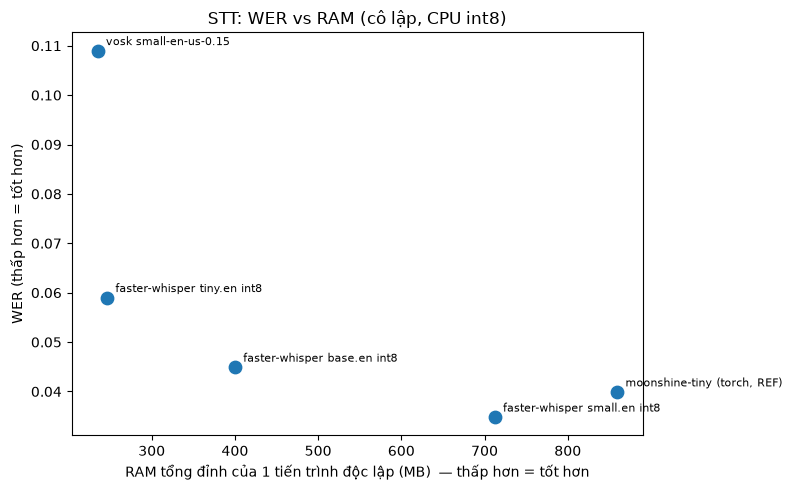

In [9]:
plot_tradeoff(df, "ram_total_peak_mb", "wer", "STT: WER vs RAM (cô lập, CPU int8)", "WER (thấp hơn = tốt hơn)", "stt_lite.png")